In [152]:
!sudo apt-get update -qq
!sudo apt-get install -y -qq --no-install-recommends openjdk-17-jre-headless
%pip install -q lxml pyspark sympy matplotlib

debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (Can't locate Term/ReadLine.pm in @INC (you may need to install the Term::ReadLine module) (@INC entries checked: /etc/perl /usr/local/lib/x86_64-linux-gnu/perl/5.40.1 /usr/local/share/perl/5.40.1 /usr/lib/x86_64-linux-gnu/perl5/5.40 /usr/share/perl5 /usr/lib/x86_64-linux-gnu/perl-base /usr/lib/x86_64-linux-gnu/perl/5.40 /usr/share/perl/5.40 /usr/local/lib/site_perl) at /usr/share/perl5/Debconf/FrontEnd/Readline.pm line 8, <STDIN> line 1.)
debconf: falling back to frontend: Teletype
(Reading database ... 9849 files and directories currently installed.)
Preparing to unpack .../openjdk-17-jre-headless_17.0.21.0.3+1-1~26.04.1_amd64.deb ...
Unpacking openjdk-17-jre-headless:

In [2]:
import os, sys, subprocess
os.environ["PYSPARK_PYTHON"] = sys.executable

print(subprocess.run(["java", "-version"], capture_output=True, text=True).stderr)

from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .appName("lab1")
         .master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
sc = spark.sparkContext

print(spark.version, sc.parallelize(range(10)).sum())

openjdk version "17.0.20.1" 2026-08-18
OpenJDK Runtime Environment (build 17.0.20.1+1-1-26.04-Ubuntu)
OpenJDK 64-Bit Server VM (build 17.0.20.1+1-1-26.04-Ubuntu, mixed mode, sharing)



Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/07 18:24:06 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
[Stage 0:>                                                        (0 + 14) / 14]

4.3.0 45


In [134]:
from pathlib import Path
from lxml import etree

def load_nysk(path, limit=None):
    raw = Path(path).read_bytes()
    start = raw.find(b"<document>")
    body = b"<root>" + raw[start:] + b"</root>"

    parser = etree.XMLParser(recover=True, huge_tree=True)
    root = etree.fromstring(body, parser)

    docs, titles = [], {}
    
    for doc in root.iterfind("document"):
        docid = int(doc.findtext("docid").strip())
        text = (doc.findtext("text") or "").strip()
        docs.append((docid, text))
        titles[docid] = " ".join((doc.findtext("title") or "").split())
        
        if limit and len(docs) >= limit:
            break
            
    return docs, titles

In [83]:
import zlib

class Shingling:
    def __init__(self, shingle_length: int):
        self.k = shingle_length

    def construct_k_shingles(self, text: str) -> list[int]:
        index = 0
        doc_length = len(text)
        k_shingles = set()

        while index + self.k <= doc_length:
            shingle = text[index:index + self.k]
            hashed_shingle = self._hash_shingle(shingle)
            k_shingles.add(hashed_shingle)
            index += 1

        return sorted(k_shingles)

    def _hash_shingle(self, s: str) -> int:
        return zlib.crc32(s.encode("utf-8")) 

    def normalize(self, text: str) -> str:
        return " ".join(text.lower().split())

In [117]:
import os

sh = Shingling(shingle_length=7)
dir_path = os.path.abspath("../datasets/nysk/nysk.xml")

pairs = load_nysk(dir_path, limit=100)
print(len(pairs), pairs[0][0], pairs[0][1][:80])

docs = sc.parallelize(pairs, numSlices=8)
docs = docs.filter(lambda kv: len(kv[1]) > 0)

normalized = docs.mapValues(sh.normalize)
shingled = normalized.mapValues(sh.construct_k_shingles)
shingled.cache()
print(shingled.count(), "documents")

100 0 The New York Post has learned that the woman accusing IMF boss Dominique Strauss
100 documents


In [98]:
class CompareSets:
    def compute_jaccard_similarity(self, shingle_list1: list[int], shingle_list2: list[int]) -> float:
        shingle_set1 = set(shingle_list1)
        shingle_set2 = set(shingle_list2)
        
        intersection_cardinality = len(shingle_set1 & shingle_set2)
        union_cardinality = len(shingle_set1 | shingle_set2)
        
        return intersection_cardinality / union_cardinality

In [113]:
key1 = 50
key2 = 85

cs = CompareSets()

a = shingled.lookup(key1)
b = shingled.lookup(key2)

sim = cs.compute_jaccard_similarity(a[0], b[0])
print(f"{key1} vs {key2}: {sim:.4f}")
print(len(a[0]), len(b[0]))

50 vs 85: 0.0252
1906 8647


In [107]:
from sympy import nextprime
from random import Random

class MinHashing:
    def __init__(self, signature_size: int, seed: int = 42):
        self.n = signature_size
        self.c = int(nextprime(2**32 - 1))

        rng = Random(seed)

        self.a = [rng.randint(1, self.c - 1) for _ in range(self.n)]
        self.b = [rng.randint(0, self.c - 1) for _ in range(self.n)]

    def build_minhash_signature(self, hashed_shingles: list[int]) -> list[int]:
        if not hashed_shingles:
            return [self.c] * self.n
    
        return [
            min((a * s + b) % self.c for s in hashed_shingles)
            for a, b in zip(self.a, self.b)
        ]

In [118]:
mh = MinHashing(signature_size=200)
minhashed = shingled.mapValues(mh.build_minhash_signature)

minhashed.cache()
print(minhashed.count(), "documents")

key = 15
sig = minhashed.lookup(key)[0]
print(sig)

[Stage 126:==========================================>              (6 + 2) / 8]

100 documents
[727242, 399228, 1403071, 1918962, 849080, 2148323, 1897100, 159599, 56490, 84800, 1300031, 495618, 410742, 6881, 981805, 1171799, 1347653, 574015, 10003, 760093, 552415, 318010, 82194, 866499, 918630, 459622, 654528, 304595, 1004521, 570669, 2059233, 54879, 805830, 16276, 779618, 1037877, 266739, 52333, 420136, 75528, 140151, 1578364, 1072193, 421907, 615481, 155849, 289731, 1405153, 170917, 607264, 61734, 724377, 904786, 728138, 543843, 1037967, 251176, 259885, 143416, 912383, 303713, 489104, 119586, 225246, 595366, 156798, 197596, 35495, 283856, 246515, 1654710, 163118, 111375, 51828, 883171, 244156, 913523, 556441, 2709936, 438261, 293652, 1578215, 2912, 517258, 1051407, 1199770, 374556, 540097, 270223, 1001429, 458671, 1121078, 235648, 36145, 439015, 155732, 177487, 462224, 1095943, 140803, 64662, 411501, 1060101, 192301, 78517, 728585, 213195, 40669, 101447, 199322, 601084, 136603, 302760, 577468, 354068, 1255020, 477590, 701693, 345934, 139567, 340410, 541037, 6713

In [109]:
class CompareSignatures:
    def evaluate_signature_similarity(self, signature1: list[int], signature2: list[int]) -> float:
        if len(signature1) != len(signature2):
            raise ValueError(
                f"signature lengths differ: {len(signature1)} vs {len(signature2)}"
            )
        return sum(x == y for x, y in zip(signature1, signature2)) / len(signature1)

In [149]:
cs = CompareSets()
csig = CompareSignatures()

key1 = 15
key2 = 79

sig1 = minhashed.lookup(key1)
sig2 = minhashed.lookup(key2)
sig1, sig2 = sig1[0], sig2[0]

est = csig.evaluate_signature_similarity(sig1, sig2)

set1 = shingled.lookup(key1)[0]
set2 = shingled.lookup(key2)[0]
true = cs.compute_jaccard_similarity(set1, set2)

print(f"estimated (MinHash, n={len(sig1)}): {est:.4f}")
print(f"true Jaccard:                       {true:.4f}")
print(f"abs error:                          {abs(est - true):.4f}")

estimated (MinHash, n=100): 0.9600
true Jaccard:                       0.9574
abs error:                          0.0026


In [129]:
import zlib
from itertools import combinations

class LSH:
    def __init__(self, num_of_bands: int, band_size: int):
        self.b = num_of_bands
        self.r = band_size

    def _band_keys(self, signature: list[int]) -> list[tuple]:
        if len(signature) != self.b * self.r:
            raise ValueError(
                f"signature length does not fit band count and size: {len(signature)} vs {self.b * self.r}"
            )
        
        return [
            (i, self._hash_band(tuple(signature[i * self.r : (i + 1) * self.r])))
            for i in range(self.b)
        ]

    def _hash_band(self, values: tuple) -> int:
        return zlib.crc32(repr(values).encode("utf-8"))
    
    def find_candidate_pairs(self, signatures_rdd, s: float):
        b_keys = self._band_keys
        
        buckets = signatures_rdd.flatMap(lambda kv: [(key, kv[0]) for key in b_keys(kv[1])])
        shared = buckets.groupByKey().mapValues(list).filter(lambda kv: len(kv[1]) >= 2)
        pairs = shared.flatMap(lambda kv: combinations(sorted(kv[1]), 2)).distinct()

        sig_bc = signatures_rdd.context.broadcast(signatures_rdd.collectAsMap())
        comparer = CompareSignatures()
    
        def with_similarity(pair):
            id1, id2 = pair
            sigs = sig_bc.value
            return (id1, id2, comparer.evaluate_signature_similarity(sigs[id1], sigs[id2]))
    
        return pairs.map(with_similarity).filter(lambda t: t[2] >= s)

In [148]:
N, K, N_HASH, B, R, S = 100, 10, 100, 10, 10, 0.3
pairs_list, titles = load_nysk("../datasets/nysk/nysk.xml", limit=N)

sh = Shingling(K)
mh = MinHashing(signature_size=N_HASH)
lsh = LSH(B, R)

docs = sc.parallelize(pairs_list, numSlices=8).filter(lambda kv: len(kv[1]) > 0)
shingled = docs.mapValues(sh.normalize).mapValues(sh.construct_k_shingles).cache()
minhashed = shingled.mapValues(mh.build_minhash_signature).cache()

similar = lsh.find_candidate_pairs(minhashed, S)
result = similar.collect()

print(f"{len(result)} similar pairs (s >= {S})")
for id1, id2, sim in sorted(result, key=lambda t: -t[2])[:10]:
    print(f"{sim:.2f}  [{id1}] {titles[id1][:60]}")
    print(f"      [{id2}] {titles[id2][:60]}")

[Stage 229:===================================>                     (5 + 3) / 8]

3 similar pairs (s >= 0.3)
0.96  [15] Posh, pricey NYC house arrest for ex-IMF leader
      [79] Posh, pricey NYC house arrest for ex-IMF leader
0.85  [19] French politician on suicide watch in New York
      [83] NYC maid's lawyer: Assault complaint vs. IMF chief wasn't a 
0.72  [54] Former IMF chief's DNA matches sample on maid's clothes, sou
      [93] DNA evidence said to link ex-IMF leader to NY maid


In [156]:
import time

all_pairs, titles = load_nysk("../datasets/nysk/nysk.xml")
print(len(all_pairs), "articles available")

def timed(fn):
    t0 = time.perf_counter()
    out = fn()
    return out, time.perf_counter() - t0

def run_pipeline(n):
    sh, mh, lsh = Shingling(K), MinHashing(signature_size=N_HASH), LSH(B, R)
    times = {}

    docs = sc.parallelize(all_pairs[:n], numSlices=64).filter(lambda kv: len(kv[1]) > 0)
    shingled = docs.mapValues(sh.normalize).mapValues(sh.construct_k_shingles).cache()
    _, times["shingling"] = timed(shingled.count)

    minhashed = shingled.mapValues(mh.build_minhash_signature).cache()
    _, times["minhash"] = timed(minhashed.count)

    result, times["lsh"] = timed(lambda: lsh.find_candidate_pairs(minhashed, S).collect())

    shingled.unpersist(); minhashed.unpersist()
    return len(result), times

run_pipeline(10)                                              

sizes = [100, 1000, 10000]
results = {}

for n in sizes:
    runs = [run_pipeline(n) for _ in range(3)]
    pairs_found = runs[0][0]
    median = {k: sorted(r[1][k] for r in runs)[1] for k in runs[0][1]}
    results[n] = {"pairs": runs[0][0], **median}
    print(n, results[n])

10421 articles available


100 {'pairs': 3, 'shingling': 0.6064037430041935, 'minhash': 1.1685040640004445, 'lsh': 1.1683036089816596}


1000 {'pairs': 146, 'shingling': 0.8352159319911152, 'minhash': 6.688817782996921, 'lsh': 1.6052145569992717}


[Stage 295:=======================================>              (47 + 15) / 64]

10000 {'pairs': 14455, 'shingling': 3.3948635720007587, 'minhash': 64.37603292497806, 'lsh': 2.3999830500106327}


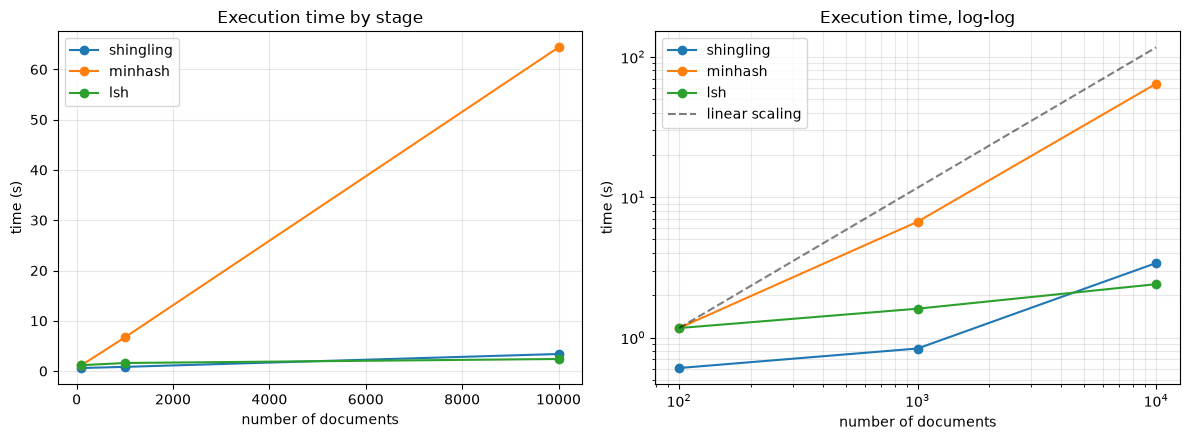

In [158]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for stage in ["shingling", "minhash", "lsh"]:
    axes[0].plot(sizes, [results[n][stage] for n in sizes], marker="o", label=stage)

axes[0].set(xlabel="number of documents", ylabel="time (s)", title="Execution time by stage")
axes[0].legend()
axes[0].grid(alpha=0.3)

for stage in ["shingling", "minhash", "lsh"]:
    axes[1].loglog(sizes, [results[n][stage] for n in sizes], marker="o", label=stage)
    
ref = [results[sizes[0]]["minhash"] * n / sizes[0] for n in sizes]
axes[1].loglog(sizes, ref, "k--", alpha=0.5, label="linear scaling")

axes[1].set(xlabel="number of documents", ylabel="time (s)", title="Execution time, log-log")
axes[1].legend()
axes[1].grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()